In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm
import numpy as np
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

Mearge two files

In [2]:
DATA1 = Path('../data/processed')
DATA2 = Path('../data/external')
#CACHE = DATA / 'cache'
domains_df = pd.read_parquet(DATA1 / 'all_publications_enriched.parquet')
researchers_df = pd.read_parquet(DATA2 / 'papers_cleaned.gencat.parquet')
# Merge on DOI
merged_df = researchers_df.merge(
    domains_df[["doi", "domain_name", "year"]],
    on="doi",
    how="left"
)

# Keep columns in the desired order
merged_df = merged_df[[
    "year",
    "doi",
    "orcidResearchers",
    "domain_name"
]]

# Save as parquet
output_file = "merged_data.parquet"
merged_df.to_parquet(output_file, index=False)

print(f"Saved {len(merged_df):,} rows to {output_file}")
print(merged_df.head())

Saved 21,036,994 rows to merged_data.parquet
   year                                 doi       orcidResearchers  \
0  1949                10.1210/jcem-9-9-883  [0000-0002-6245-7933]   
1  1952            10.1002/cber.19520850704  [0000-0001-6112-5913]   
2  1952  10.1111/j.1365-2133.1952.tb15900.x  [0000-0002-6245-7933]   
3  1953                 10.1038/jid.1953.55  [0000-0002-6245-7933]   
4  1954       10.1016/s0022-5347(17)67795-4  [0000-0002-6245-7933]   

         domain_name  
0    Health Sciences  
1  Physical Sciences  
2    Health Sciences  
3      Life Sciences  
4    Health Sciences  


In [3]:
cleaned_papers = pd.read_parquet(DATA1 / 'publications_research_year_domain.parquet')
cleaned_papers = cleaned_papers.drop_duplicates(subset="doi")

In [4]:
domains = []
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Health Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Physical Sciences'])
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Life Sciences']) 
domains.append(cleaned_papers[cleaned_papers['domain_name'] == 'Social Sciences']) 

exploded_domains = []
for i in range(0,4):
    exploded_domains.append(domains[i].explode('orcidResearchers'))
grouped = []
difs = []
difs_norm = []
for i in range(0,4):
    grouped.append(exploded_domains[i]['orcidResearchers'].value_counts())
    vc = grouped[i].value_counts().sort_index()            # counts per value, ascending x

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    
    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)
    # Area under the curve
    area = np.trapezoid(x, y)

    # Normalize so area = 1
    if area < 0:
        x_norm = x / (-area)
    else:
        x_norm = x
    difs.append([dif['value'],dif["surv_ge"]])
    difs_norm.append([x_norm,y])
print('ja està!')

ja està!


In [62]:
all_data = np.vstack([
    np.column_stack((difs_norm[i][0], difs_norm[i][1]))
    for i in range(4)
])
# Extract x and y
x_all = all_data[:, 0]
y_all = all_data[:, 1]

# Remove invalid values
valid = (
    np.isfinite(x_all) &
    np.isfinite(y_all) &
    (x_all >= 0) &
    (y_all > 0)
)

x_all = x_all[valid]
y_all = y_all[valid]

# Sort data by x
order = np.argsort(x_all)

x_all = x_all[order]
y_all = y_all[order]

# Merged dataset: [x_norm, y]
all_data = np.column_stack((x_all, y_all))


# =====================================================
# 4. Define weighted double exponential regression
# =====================================================

def double_exponential(x, a, b, c, d,e,f):

    return (
        a * np.exp(-b * x) +
        c * np.exp(-d * x) +
        e * np.exp(-f * x)
    )


# =====================================================
# 5. Calculate weights to emphasize the long tail
# =====================================================

# Smaller y values (long tail) receive greater weight
weights = 1 / np.sqrt(y_all)

# Normalize weights
weights = weights / np.mean(weights)

# =====================================================
# 6. Perform weighted regression
# =====================================================

# Initial parameter estimates
p0 = [
    0.7 * np.max(y_all), 0.1,
    0.3 * np.max(y_all), 0.01,
    0.2 * np.max(y_all), 0.05
]

popt, pcov = curve_fit(
    double_exponential,
    x_all,
    y_all,
    p0=p0,

    # curve_fit minimizes residuals weighted by 1/sigma
    sigma= 1/weights**1.5,
    absolute_sigma=False,

    # Positive amplitudes and decay rates
    bounds=(
        [0, 1e-10, 0, 1e-10,0, 1e-10],
        [np.inf, np.inf, np.inf, np.inf,np.inf, np.inf]
    ),

    maxfev=100000
)

x_fit = np.linspace(0, 60, 1000)
y_fit = double_exponential(x_fit, *popt)


# =====================================================
# 7. Calculate predictions and goodness of fit
# =====================================================

y_pred = double_exponential(x_all, *popt)

r2 = r2_score(y_all, y_pred)

# Weighted R²
weighted_mean = np.average(y_all, weights=weights**2)

ss_res = np.sum(weights**2 * (y_all - y_pred)**2)
ss_tot = np.sum(weights**2 * (y_all - weighted_mean)**2)

weighted_r2 = 1 - ss_res / ss_tot


# =====================================================
# 8. Print regression results
# =====================================================

a, b, c, d,e,f = popt

print("\nWEIGHTED TRIPLE EXPONENTIAL REGRESSION")
print("--------------------------------------")

print(f"y = {a:.6f} * exp(-{b:.6f} * x) "
      f"+ {c:.6f} * exp(-{d:.6f} * x)"
     f"+ {e:.6f} * exp(-{f:.6f} * x)")

print(f"\nR² = {r2:.6f}")
print(f"Weighted R² = {weighted_r2:.6f}")

print(f"\na = {a:.6f}")
print(f"b = {b:.6f}")
print(f"c = {c:.6f}")
print(f"d = {d:.6f}")
print(f"e = {e:.6f}")
print(f"f = {f:.6f}")




WEIGHTED TRIPLE EXPONENTIAL REGRESSION
--------------------------------------
y = 0.636618 * exp(-2.831189 * x) + 0.301365 * exp(-0.496442 * x)+ 0.014799 * exp(-0.107110 * x)

R² = 0.980952
Weighted R² = 0.983861

a = 0.636618
b = 2.831189
c = 0.301365
d = 0.496442
e = 0.014799
f = 0.107110


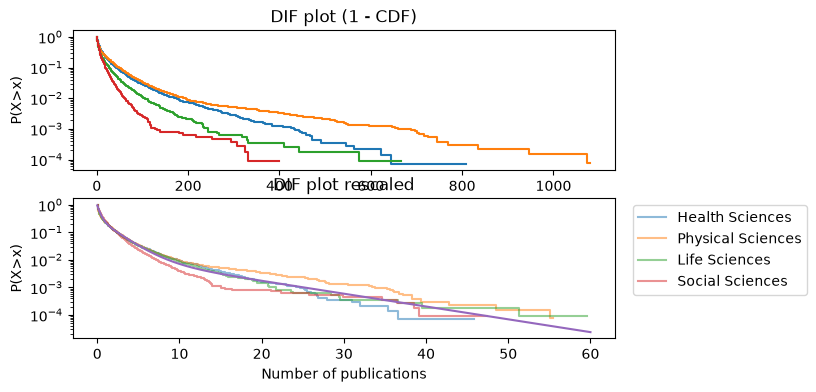

In [65]:
fig, ax = plt.subplots(nrows=2,ncols=1,figsize=(7, 4))
fields_labels = ['Health Sciences','Physical Sciences','Life Sciences','Social Sciences']
for i in range(0,4):
    ax[0].step(difs[i][0], difs[i][1],label = fields_labels[i])
ax[0].set_xlabel("Number of publications")
ax[0].set_ylabel("P(X>x)")
ax[0].set_title("DIF plot (1 - CDF)")
#ax[0].set_xscale("log")
ax[0].set_yscale("log")

for i in range(0,4):
    ax[1].step(difs_norm[i][0], difs_norm[i][1],label = fields_labels[i],alpha = 0.5)
ax[1].plot(x_fit,y_fit)
ax[1].set_xlabel("Number of publications")
ax[1].set_ylabel("P(X>x)")
ax[1].set_title("DIF plot rescaled")
#ax[1].set_xlim(right=10)
#ax[1].set_ylim(bottom=10**(-3))
#ax[1].set_xscale("log")
ax[1].set_yscale("log")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()